# 07 – Data Validation, Outlier Handling & Feature Engineering
**Telecom Customer Intelligence & Retention Platform**

**Goal:** turn the three raw tables into ONE clean, customer-level table (one row per customer) that is ready for modeling.

**Order of work (and why):**
1. Load the **raw** files (nothing imputed yet).
2. Remove duplicate customers.
3. **Outlier check + removal on raw data – BEFORE building any feature**, so bad values cannot contaminate means, stds, slopes, etc.
4. Build features from the usage table (per customer) and the customer table.
5. Merge into one table, join the churn label last.
6. Sanity-check with a baseline model (customer-level split, imputation fitted on train only).
7. Save `customer_features.csv`.

## 1. Setup and load raw data

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)

# works whether the notebook is run from notebooks/ or from the project root
RAW = next(p for p in [Path("../data/raw"), Path("data/raw")] if p.exists())
OUT = RAW.parent / "processed"; OUT.mkdir(exist_ok=True)

info  = pd.read_csv(RAW / "customer_info.csv")
usage = pd.read_csv(RAW / "usage_data.csv")
churn = pd.read_csv(RAW / "churn_labels.csv")

info  = info.rename(columns={"CustomerID":"customer_id","Age":"age","Gender":"gender","Region":"region",
                             "ContractType":"contract_type","MonthlyCharges":"monthly_charges","SignupDate":"signup_date"})
usage = usage.rename(columns={"CustomerID":"customer_id","Month":"month","CallMinutes":"call_minutes",
                              "DataUsageGB":"data_usage_gb","SMSCount":"sms_count","Complaints":"complaints"})
churn = churn.rename(columns={"CustomerID":"customer_id","Churn":"churn"})

usage["month"] = pd.to_datetime(usage["month"]).dt.month      # keep month number 1..12
info["signup_date"] = pd.to_datetime(info["signup_date"])

print("customer_info:", info.shape, "| usage_data:", usage.shape, "| churn_labels:", churn.shape)
info.head()

customer_info: (10200, 7) | usage_data: (120000, 6) | churn_labels: (10000, 2)


,customer_id,age,gender,region,contract_type,monthly_charges,signup_date
0,CUST_0,NaN,Male,Urban,Yearly,48.18,2021-03-20
1,CUST_1,NaN,Female,Suburban,Prepaid,38.94,2020-01-25
2,CUST_2,46.0,Female,Rural,Monthly,48.56,2022-08-31
3,CUST_3,NaN,Female,Urban,Prepaid,24.22,2018-12-09
4,CUST_4,60.0,Male,Rural,Monthly,67.86,2022-12-28


## 2. Duplicate customers

In [2]:
print("Exact duplicate rows in customer_info:", info.duplicated().sum())
info = info.drop_duplicates()
dups = info[info.customer_id.duplicated(keep=False)].sort_values("customer_id")
print("Customers still duplicated with CONFLICTING details:", dups.customer_id.nunique())
dups

Exact duplicate rows in customer_info: 195
Customers still duplicated with CONFLICTING details: 5


,customer_id,age,gender,region,contract_type,monthly_charges,signup_date
248,CUST_248,22.0,Male,Rural,Monthly,58.85,2022-09-06
10024,CUST_248,22.0,Male,Rural,Monthly,58.85,2022-06-09
308,CUST_308,37.0,Male,Urban,Monthly,42.28,2018-01-03
10144,CUST_308,37.0,Male,Urban,Monthly,42.28,2018-03-01
333,CUST_333,NaN,Male,Rural,Prepaid,63.64,2023-11-02
10089,CUST_333,NaN,Male,Rural,Prepaid,63.64,2023-02-11
391,CUST_391,NaN,Female,Urban,Yearly,31.60,2023-11-03
10150,CUST_391,NaN,Female,Urban,Yearly,31.60,2023-03-11
466,CUST_466,23.0,Female,Urban,Monthly,45.18,2021-03-07
10076,CUST_466,23.0,Female,Urban,Monthly,45.18,2021-07-03


Five customers appear twice with different details (e.g. different signup dates). We keep the **earliest signup date** for each (same decision you made manually earlier).
Note: these 5 customers are exactly what produced the extra 60 usage rows (5 × 12 months) after merging in the earlier notebooks.

In [3]:
info = (info.sort_values(["customer_id","signup_date"]).drop_duplicates("customer_id", keep="first")
            .reset_index(drop=True))
print("customer_info after de-duplication:", info.shape, "| unique ids:", info.customer_id.nunique())
print("usage duplicates on (customer, month):", usage.duplicated(["customer_id","month"]).sum())

customer_info after de-duplication: (10000, 7) | unique ids: 10000
usage duplicates on (customer, month): 0


## 3. Outlier check and removal (BEFORE feature engineering)
Two kinds of "outlier" are treated differently:
- **Errors** (impossible or detached from the data) → removed.
- **Extreme but plausible** values → kept (they may be genuine heavy users or genuine churners).

First, look at the raw ranges of every column.

In [4]:
print(info[["age","monthly_charges"]].describe().round(2))
print()
print(usage[["call_minutes","data_usage_gb","sms_count","complaints"]].describe().round(2))
print("\nMonths present:", sorted(usage.month.unique()))

           age  monthly_charges
count  6500.00         10000.00
mean     43.42            51.00
std      14.97            21.54
min      18.00            -6.72
25%      31.00            39.80
50%      43.00            50.02
75%      56.00            60.50
max      69.00           390.30

       call_minutes  data_usage_gb  sms_count  complaints
count     120000.00      120000.00  120000.00   120000.00
mean         492.40           9.90      24.53        0.50
std          117.44           3.07      14.42        0.71
min           34.14           0.00       0.00        0.00
25%          418.45           7.81      12.00        0.00
50%          494.96           9.92      25.00        0.00
75%          571.08          11.98      37.00        1.00
max          914.16          22.73      49.00        6.00

Months present: [np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12)]


### 3.1 Rule-based check: impossible values

In [5]:
checks = {
    "negative call minutes":        (usage.call_minutes < 0).sum(),
    "negative data usage":          (usage.data_usage_gb < 0).sum(),
    "negative SMS":                 (usage.sms_count < 0).sum(),
    "negative complaints":          (usage.complaints < 0).sum(),
    "month outside 1-12":           (~usage.month.between(1, 12)).sum(),
    "age outside 15-100":           (info.age.notna() & ~info.age.between(15, 100)).sum(),
    "monthly charges <= 0":         (info.monthly_charges <= 0).sum(),
}
pd.Series(checks, name="rows affected").to_frame()

,rows affected
negative call minutes,0
negative data usage,0
negative SMS,0
negative complaints,0
month outside 1-12,0
age outside 15-100,0
monthly charges <= 0,5


Only `monthly_charges` has impossible values (zero or negative). Everything else is within valid ranges.

### 3.2 Statistical check: IQR fences (k = 3 = "far out")

In [6]:
K = 3.0
def iqr_fences(s, k=K):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return q1 - k*i, q3 + k*i

rows = []
for col, df in [("call_minutes",usage),("data_usage_gb",usage),("sms_count",usage),("complaints",usage),
                ("monthly_charges", info[info.monthly_charges > 0])]:
    lo, hi = iqr_fences(df[col])
    n = int(((df[col] < lo) | (df[col] > hi)).sum())
    rows.append([col, round(lo,2), round(hi,2), n, round(100*n/len(df),3)])
pd.DataFrame(rows, columns=["column","lower_fence","upper_fence","n_outside","% of rows"])

,column,lower_fence,upper_fence,n_outside,% of rows
0,call_minutes,-39.44,1028.97,0,0.000
1,data_usage_gb,-4.70,24.49,0,0.000
2,sms_count,-63.00,112.00,0,0.000
3,complaints,-3.00,4.00,25,0.021
4,monthly_charges,-22.24,122.56,49,0.490


Reading the table:
- `call_minutes`, `data_usage_gb`, `sms_count`: **0 values** beyond the far-out fence → their tails are smooth and plausible. Nothing to remove.
- `complaints`: a few months with 5–6 complaints; it is a count variable, so this is plausible → **kept**.
- `monthly_charges`: values far above everything else → look closer below.

### 3.3 Look at it: is the MonthlyCharges tail real?

C:\Users\DELL\AppData\Local\Temp\ipykernel_24476\2668118375.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[1].boxplot(c, vert=False); ax[1].set_title("MonthlyCharges – box plot")


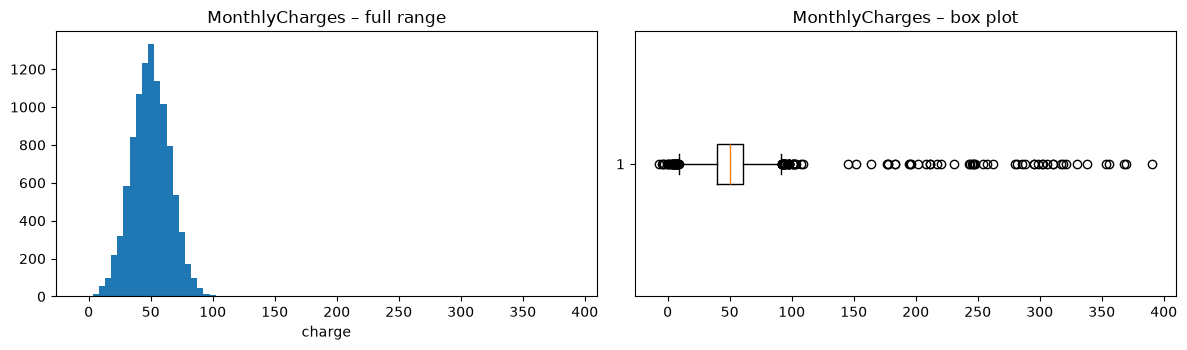

Largest: [390.3, 369.6, 367.6, 356.0, 353.4, 338.1, 330.0, 321.5, 318.5, 316.8, 310.8, 310.5]
Smallest: [-6.7, -4.6, -3.9, -3.2, -0.5, 0.4, 0.7, 1.1]


In [7]:
c = info.monthly_charges
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(c, bins=80); ax[0].set_title("MonthlyCharges – full range"); ax[0].set_xlabel("charge")
ax[1].boxplot(c, vert=False); ax[1].set_title("MonthlyCharges – box plot")
plt.tight_layout(); plt.show()
print("Largest:", c.nlargest(12).round(1).tolist())
print("Smallest:", c.nsmallest(8).round(1).tolist())

The bulk of customers pay about 40–60 (std ≈ 15), but a small group sits at 250–390: more than 5× the typical bill and detached from the main distribution. Together with the negative/zero values, this pattern looks like **data errors**, not real customers, so they are removed.

### 3.4 Removal
- **Action = "nan"**: blank the bad *value* but **keep the customer** (the customer's usage history is still valid, and only ~54 of 10,000 customers are affected). The missing charges are imputed later, inside the modeling pipeline, using the training set only.
- Alternative **"drop"**: remove the whole customer. Not the default because it also deletes churners from a rare class (7.86%).

In [8]:
ACTION = "nan"            # "nan" = blank the bad value, keep customer | "drop" = remove customer

lo, hi = iqr_fences(info.loc[info.monthly_charges > 0, "monthly_charges"])
impossible = info.monthly_charges <= 0
extreme    = info.monthly_charges > hi
bad = impossible | extreme
print(f"Upper fence = {hi:.2f} | impossible: {impossible.sum()} | extreme: {extreme.sum()} | total: {bad.sum()}")

if ACTION == "drop":
    gone = set(info.loc[bad, "customer_id"])
    info  = info[~bad]; usage = usage[~usage.customer_id.isin(gone)]
else:
    info.loc[bad, "monthly_charges"] = np.nan

# usage rows with impossible values (none found, kept for safety)
bad_usage = (usage[["call_minutes","data_usage_gb","sms_count","complaints"]] < 0).any(axis=1) | ~usage.month.between(1,12)
usage = usage[~bad_usage]
print("usage rows removed as impossible:", int(bad_usage.sum()))
print(info.monthly_charges.describe().round(2))

Upper fence = 122.56 | impossible: 5 | extreme: 49 | total: 54
usage rows removed as impossible: 0
count    9946.00
mean       50.00
std        15.19
min         0.38
25%        39.74
50%        49.93
75%        60.35
max       109.08
Name: monthly_charges, dtype: float64


**Why these fences are safe to compute on all data:** they use no churn label, so nothing about the target leaks. (Imputation, scaling and any capping that is later *fitted* should still be done on the training set only.)

## 4. Feature engineering
Now that the data is clean we can build features.

### 4.1 Usage features: 12 monthly rows → 1 row per customer
We only use **months 1–`WINDOW`** so the last months stay outside the feature window (reduces the risk that features are built from the same period as the churn outcome).

In [9]:
WINDOW = 9
w = usage[usage.month <= WINDOW].sort_values(["customer_id","month"])
g = w.groupby("customer_id")

def slope(s):                                   # linear trend across the months
    return float(np.polyfit(np.arange(len(s)), s.to_numpy(), 1)[0]) if len(s) > 1 else 0.0

recent = w[w.month > WINDOW - 3].groupby("customer_id")      # last 3 months of the window
early  = w[w.month <= 3].groupby("customer_id")              # first 3 months

uf = pd.DataFrame(index=g.size().index)
for col in ["call_minutes","data_usage_gb","sms_count"]:
    uf[f"{col}_mean"]  = g[col].mean()                       # baseline engagement
    uf[f"{col}_std"]   = g[col].std()                        # erratic usage
    uf[f"{col}_min"]   = g[col].min()                        # inactivity months
    uf[f"{col}_max"]   = g[col].max()                        # peak need
    uf[f"{col}_slope"] = g[col].apply(lambda s: slope(s))    # direction of travel
    uf[f"{col}_recent_vs_early"] = recent[col].mean() / early[col].mean().replace(0, np.nan)  # decline ratio
    uf[f"{col}_cv"]    = uf[f"{col}_std"] / uf[f"{col}_mean"].replace(0, np.nan)             # relative volatility

uf["complaints_total"]   = g.complaints.sum()                               # overall dissatisfaction
uf["complaints_mean"]    = g.complaints.mean()
uf["complaint_months"]   = g.complaints.apply(lambda s: int((s > 0).sum()))  # persistent vs one-off
uf["complaints_recent3"] = recent.complaints.sum()                          # recent unresolved issues
uf["active_months"]      = g.month.nunique()
uf = uf.reset_index()
print(uf.shape); uf.head()

(10000, 27)


,customer_id,call_minutes_mean,call_minutes_std,call_minutes_min,call_minutes_max,call_minutes_slope,call_minutes_recent_vs_early,call_minutes_cv,data_usage_gb_mean,data_usage_gb_std,data_usage_gb_min,data_usage_gb_max,data_usage_gb_slope,data_usage_gb_recent_vs_early,data_usage_gb_cv,sms_count_mean,sms_count_std,sms_count_min,sms_count_max,sms_count_slope,sms_count_recent_vs_early,sms_count_cv,complaints_total,complaints_mean,complaint_months,complaints_recent3,active_months
0,CUST_0,493.412222,53.726309,434.82,590.26,3.309000,1.063940,0.108887,9.285556,2.813348,5.99,14.16,0.102667,0.982822,0.302981,26.000000,11.958261,9,41,1.683333,1.482759,0.459933,6,0.666667,5,0,9
1,CUST_1,457.194444,52.600385,396.88,564.07,-2.347833,1.005550,0.115050,10.083333,3.699392,3.45,15.68,-0.330000,0.896754,0.366882,32.000000,14.186261,1,47,-1.533333,0.882979,0.443321,8,0.888889,6,2,9
2,CUST_10,617.418889,38.419769,534.43,658.84,-6.131167,0.923437,0.062226,8.223333,5.053736,0.00,12.53,0.363500,1.268957,0.614561,18.333333,11.853270,3,40,-2.450000,0.545455,0.646542,11,1.222222,7,5,9
3,CUST_100,529.485556,52.952794,433.72,582.60,0.688000,1.012179,0.100008,9.123333,3.468923,5.43,14.55,0.388500,1.348727,0.380225,30.444444,13.087314,5,46,0.650000,1.337662,0.429875,5,0.555556,5,2,9
4,CUST_1000,506.097778,51.530110,455.05,600.54,-7.330167,0.971527,0.101818,10.765556,2.694305,6.39,13.90,0.234167,1.246481,0.250271,21.111111,13.411231,0,40,-3.566667,0.290323,0.635269,10,1.111111,7,4,9


**What each usage feature means**
| Feature | Meaning / why it helps |
|---|---|
| `*_mean` | Baseline engagement; low users have less reason to stay |
| `*_std`, `*_cv` | Instability of usage (cv = std relative to size) |
| `*_min` / `*_max` | Inactive months / peak need |
| `*_slope` | Trend; negative = declining engagement (early warning) |
| `*_recent_vs_early` | Last 3 months ÷ first 3 months; <1 means usage dropped |
| `complaints_*` | Dissatisfaction: total, persistence, and recency |
| `active_months` | Gaps / late signups |

### 4.2 Customer features

In [10]:
REF_DATE = pd.Timestamp("2023-12-31")        # same reference date as the SQL analytics

cf = info.copy()
cf["age_missing"]  = cf.age.isna().astype(int)                       # missingness can itself carry signal
cf["tenure_months"] = ((REF_DATE - cf.signup_date).dt.days // 30).astype(int)
cf["signed_up_after_window_start"] = (cf.signup_date > pd.Timestamp("2023-01-31")).astype(int)
cf = cf.drop(columns="signup_date")
print("Age is left as NaN on purpose (imputed later on train only). Missing:", cf.age.isna().sum())
cf.head()

Age is left as NaN on purpose (imputed later on train only). Missing: 3500


,customer_id,age,gender,region,contract_type,monthly_charges,age_missing,tenure_months,signed_up_after_window_start
0,CUST_0,NaN,Male,Urban,Yearly,48.18,1,33,0
1,CUST_1,NaN,Female,Suburban,Prepaid,38.94,1,47,0
2,CUST_10,NaN,Female,Urban,Prepaid,47.81,1,20,0
3,CUST_100,62.0,Female,Urban,Monthly,29.80,0,26,0
4,CUST_1000,NaN,Female,Suburban,Monthly,61.62,1,67,0


### 4.3 Merge into one customer-level table (label joined last)

In [11]:
df = cf.merge(uf, on="customer_id", how="inner")

# value-for-money: paying a lot for little usage is a classic churn driver
df["data_gb_per_charge"]  = df.data_usage_gb_mean / df.monthly_charges.replace(0, np.nan)
df["minutes_per_charge"]  = df.call_minutes_mean  / df.monthly_charges.replace(0, np.nan)

df = df.merge(churn, on="customer_id", how="inner")
assert df.customer_id.is_unique, "expected one row per customer"
print("Final table:", df.shape, "| churn rate:", round(df.churn.mean()*100, 2), "%")
print("\nMissing values (imputed later in the Pipeline):")
print(df.isna().sum()[df.isna().sum() > 0])
df.head()

Final table: (10000, 38) | churn rate: 7.86 %

Missing values (imputed later in the Pipeline):
age                   3500
monthly_charges         54
data_gb_per_charge      54
minutes_per_charge      54
dtype: int64


,customer_id,age,gender,region,contract_type,monthly_charges,age_missing,tenure_months,signed_up_after_window_start,call_minutes_mean,call_minutes_std,call_minutes_min,call_minutes_max,call_minutes_slope,call_minutes_recent_vs_early,call_minutes_cv,data_usage_gb_mean,data_usage_gb_std,data_usage_gb_min,data_usage_gb_max,data_usage_gb_slope,data_usage_gb_recent_vs_early,data_usage_gb_cv,sms_count_mean,sms_count_std,sms_count_min,sms_count_max,sms_count_slope,sms_count_recent_vs_early,sms_count_cv,complaints_total,complaints_mean,complaint_months,complaints_recent3,active_months,data_gb_per_charge,minutes_per_charge,churn
0,CUST_0,NaN,Male,Urban,Yearly,48.18,1,33,0,493.412222,53.726309,434.82,590.26,3.309000,1.063940,0.108887,9.285556,2.813348,5.99,14.16,0.102667,0.982822,0.302981,26.000000,11.958261,9,41,1.683333,1.482759,0.459933,6,0.666667,5,0,9,0.192726,10.241017,0
1,CUST_1,NaN,Female,Suburban,Prepaid,38.94,1,47,0,457.194444,52.600385,396.88,564.07,-2.347833,1.005550,0.115050,10.083333,3.699392,3.45,15.68,-0.330000,0.896754,0.366882,32.000000,14.186261,1,47,-1.533333,0.882979,0.443321,8,0.888889,6,2,9,0.258945,11.740998,0
2,CUST_10,NaN,Female,Urban,Prepaid,47.81,1,20,0,617.418889,38.419769,534.43,658.84,-6.131167,0.923437,0.062226,8.223333,5.053736,0.00,12.53,0.363500,1.268957,0.614561,18.333333,11.853270,3,40,-2.450000,0.545455,0.646542,11,1.222222,7,5,9,0.172000,12.914011,0
3,CUST_100,62.0,Female,Urban,Monthly,29.80,0,26,0,529.485556,52.952794,433.72,582.60,0.688000,1.012179,0.100008,9.123333,3.468923,5.43,14.55,0.388500,1.348727,0.380225,30.444444,13.087314,5,46,0.650000,1.337662,0.429875,5,0.555556,5,2,9,0.306152,17.767972,0
4,CUST_1000,NaN,Female,Suburban,Monthly,61.62,1,67,0,506.097778,51.530110,455.05,600.54,-7.330167,0.971527,0.101818,10.765556,2.694305,6.39,13.90,0.234167,1.246481,0.250271,21.111111,13.411231,0,40,-3.566667,0.290323,0.635269,10,1.111111,7,4,9,0.174709,8.213206,0


## 5. Quick sanity checks on the new features

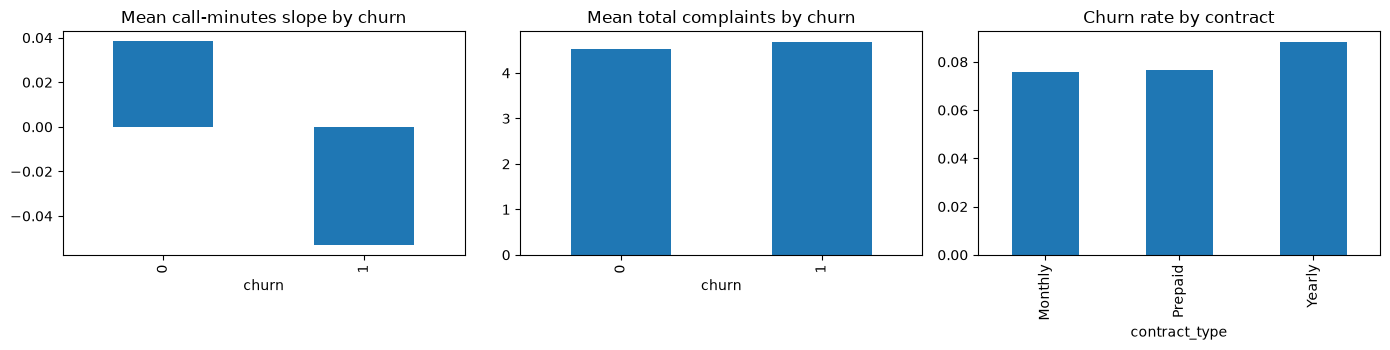

Top correlations with churn:
sms_count_cv          0.023
sms_count_mean        0.023
complaints_mean       0.021
complaints_total      0.021
complaints_recent3    0.019
call_minutes_std      0.018
complaint_months      0.017
monthly_charges       0.015
Name: churn, dtype: float64


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
df.groupby("churn")["call_minutes_slope"].mean().plot.bar(ax=ax[0], title="Mean call-minutes slope by churn")
df.groupby("churn")["complaints_total"].mean().plot.bar(ax=ax[1], title="Mean total complaints by churn")
df.groupby("contract_type")["churn"].mean().plot.bar(ax=ax[2], title="Churn rate by contract")
plt.tight_layout(); plt.show()

num = df.drop(columns=["customer_id","gender","region","contract_type"])
print("Top correlations with churn:")
print(num.corr()["churn"].drop("churn").abs().sort_values(ascending=False).head(8).round(3))

## 6. Baseline model (sanity check only)
Rules followed so the result is trustworthy:
- split **by customer** (one row per customer, so no customer is in both train and test), **stratified** on churn;
- imputation and scaling are inside a `Pipeline`, so they are **fitted on the training set only**;
- metrics: **ROC-AUC and PR-AUC** (accuracy is misleading with 7.86% churn).

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

y = df["churn"]; X = df.drop(columns=["churn","customer_id"])
cat = ["gender","region","contract_type"]; numc = [c for c in X if c not in cat]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

def make_pre():
    return ColumnTransformer([("c", OneHotEncoder(), cat),
                              ("n", Pipeline([("imp", SimpleImputer(strategy="median")),
                                              ("sc", StandardScaler())]), numc)])
res = []
for name, m in [("Logistic regression", LogisticRegression(max_iter=1000, class_weight="balanced")),
                ("Random forest", RandomForestClassifier(300, min_samples_leaf=20, class_weight="balanced",
                                                         random_state=42, n_jobs=-1))]:
    s = Pipeline([("pre", make_pre()), ("m", m)]).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
    res.append([name, round(roc_auc_score(yte, s), 3), round(average_precision_score(yte, s), 3)])
print("Churn base rate in test set:", round(yte.mean(), 3))
pd.DataFrame(res, columns=["model","ROC-AUC","PR-AUC"])

Churn base rate in test set: 0.078


,model,ROC-AUC,PR-AUC
0,Logistic regression,0.524,0.081
1,Random forest,0.498,0.078


**Reading the result:** ROC-AUC ≈ 0.5 and PR-AUC ≈ the base rate means the models are no better than chance. This agrees with the SQL finding that churners and non-churners have almost identical average usage. It points to **little or no signal in this (likely synthetic) dataset**, not to a bug in the features. Report it honestly as a limitation; do not tune to force a better score.

## 7. Save the modeling table

In [14]:
path = OUT / "customer_features.csv"
df.to_csv(path, index=False)
print("Saved:", path, df.shape)

Saved: ..\data\processed\customer_features.csv (10000, 38)


## Summary of what was done
1. Loaded raw data; removed duplicate customers (kept earliest signup for the 5 conflicting ones).
2. **Outlier check before features:** only `monthly_charges` had errors (5 impossible ≤ 0 values and ~49 far-out values above the 3×IQR fence) → those 54 values were blanked, customers kept. Usage outliers were plausible and kept.
3. Built per-customer usage features (level, variability, trend, recent-vs-early decline, complaints), customer features (age-missing flag, tenure, etc.) and value-for-money ratios.
4. Merged to one row per customer and joined the churn label last.
5. Baseline models show ≈ chance performance, so the data has little predictive signal.
6. Saved `data/processed/customer_features.csv`.

**Still to do in the modeling step:** impute `age` and `monthly_charges` inside the Pipeline (train only), optional train-fitted capping, cross-validation, threshold selection on PR curve.